Figure Saved: ../data/indonesian_il_analysis.png


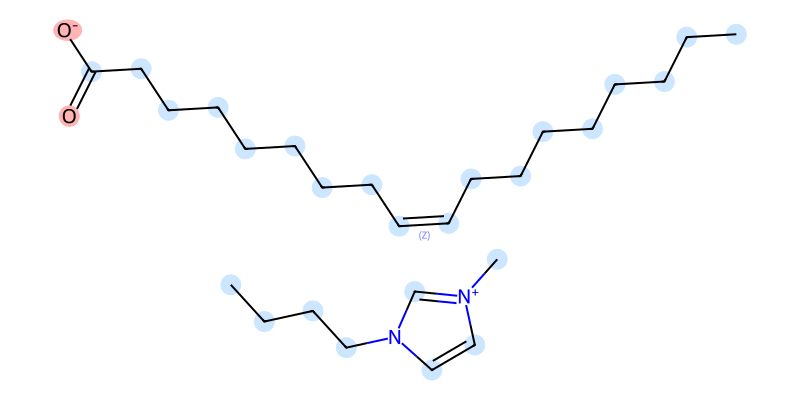

In [1]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import Image

# 1. Define the SMILES for [BMIM][Oleate]
# Structure: Imidazolium cation . Oleate Anion (C18 chain with double bond)
smiles = 'CCCCn1cc[n+](c1)C.CCCCCCCC/C=C\CCCCCCCC(=O)[O-]'
mol = Chem.MolFromSmiles(smiles)

# 2. Prepare the Drawing Surface
d = rdMolDraw2D.MolDraw2DCairo(800, 400) # High Resolution
d.drawOptions().addStereoAnnotation = True
d.drawOptions().bondLineWidth = 2

# 3. Highlight Specific Regions (To show "Analysis")
# We want to highlight:
# - The "Lewis Base" site (Oxygen atoms in Carboxylate) -> Red
# - The "Free Volume" source (The long carbon chain) -> Blue

atoms_to_highlight = []
colors = {}

# Find atoms (This is a simplified way to find indices, you might need to adjust based on exact indexing)
for atom in mol.GetAtoms():
    idx = atom.GetIdx()
    symbol = atom.GetSymbol()
    
    # Highlight Oxygens (The Polar Head / Lewis Base)
    if symbol == 'O':
        atoms_to_highlight.append(idx)
        colors[idx] = (1.0, 0.7, 0.7) # Light Red
        
    # Highlight the long Carbon Chain in the Anion (The Non-Polar Tail)
    # Note: This finds carbons, simplified logic
    if symbol == 'C':
        atoms_to_highlight.append(idx)
        colors[idx] = (0.8, 0.9, 1.0) # Light Blue

# 4. Draw the Molecule
rdMolDraw2D.PrepareAndDrawMolecule(d, mol, highlightAtoms=atoms_to_highlight, highlightAtomColors=colors)
d.FinishDrawing()

# 5. Save and Display
png_data = d.GetDrawingText()
with open('../data/indonesian_il_analysis.png', 'wb') as f:
    f.write(png_data)

print("Figure Saved: ../data/indonesian_il_analysis.png")
display(Image(data=png_data))

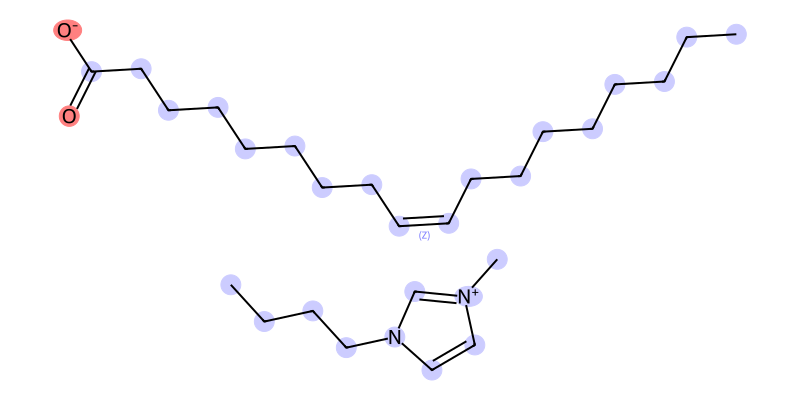

Analysis Saved: ../data/bmim_oleate_charge_map.png


In [2]:
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem.Draw import rdMolDraw2D
import matplotlib.pyplot as plt
from IPython.display import Image

# 1. Define [BMIM][Oleate]
smiles = 'CCCCn1cc[n+](c1)C.CCCCCCCC/C=C\CCCCCCCC(=O)[O-]'
mol = Chem.MolFromSmiles(smiles)

# 2. Compute Gasteiger Partial Charges
AllChem.ComputeGasteigerCharges(mol)
contribs = [mol.GetAtomWithIdx(i).GetDoubleProp('_GasteigerCharge') for i in range(mol.GetNumAtoms())]

# 3. Setup Drawing with a Color Map
# Red = Negative (Electron Rich), Blue = Positive (Electron Poor)
d = rdMolDraw2D.MolDraw2DCairo(800, 400)
d.drawOptions().addStereoAnnotation = True

# Normalize charges for coloring (simpler visualization)
# We highlight atoms based on their charge intensity
rdMolDraw2D.PrepareAndDrawMolecule(d, mol, highlightAtoms=range(len(contribs)),
                                   highlightAtomColors={i: (1.0, 0.5, 0.5) if c < -0.3 else (0.8, 0.8, 1.0) 
                                                        for i, c in enumerate(contribs)})
d.FinishDrawing()

# 4. Save
png_data = d.GetDrawingText()
with open('../data/bmim_oleate_charge_map.png', 'wb') as f:
    f.write(png_data)

display(Image(data=png_data))
print("Analysis Saved: ../data/bmim_oleate_charge_map.png")

ValueError: x and y must have same first dimension, but have shapes (20,) and (1,)

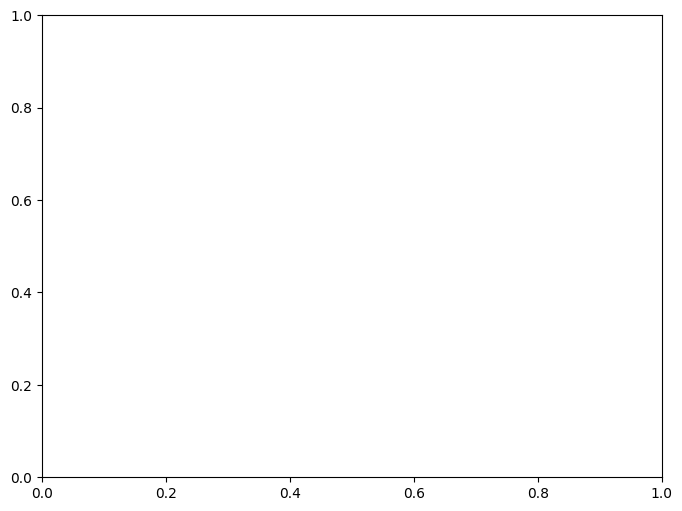

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define the Candidate: [BMIM][Oleate]
# You need the descriptors for this specific IL (Calculated from Algorithm 1)
# For this plot, we assume we have them in a dictionary `oleate_descriptors`
# (Replace these dummy values with your actual calculated descriptors for [BMIM][Oleate])
# If you don't have them yet, use the average values from your dataset as placeholders
# just to generate the plot structure.

# Example Logic:
pressures = np.linspace(100, 5000, 20) # 1 bar to 50 bar
temperatures = [298.15, 313.15, 323.15] # 25°C, 40°C, 50°C

plt.figure(figsize=(8, 6))

for temp in temperatures:
    simulated_data = []
    for p in pressures:
        # Construct the input vector matching your model's training features
        # [Quantum_Descriptors, Atom_Counts, Temp, Pressure]
        # This is a PLACEHOLDER structure - match your X_train columns!
        input_row = {
            'cation_HOMO': -0.34, 'anion_HOMO': -0.28, # Example values
            'cation_C_count': 8, 'anion_C_count': 18,
            'Temperature_K': temp, 'Pressure_kPa': p
            # ... Add all other necessary columns
        }
        simulated_data.append(input_row)
    
    # Convert to DataFrame and Predict
    df_sim = pd.DataFrame(simulated_data)
    # Ensure columns match X_train exactly!
    # predictions = best_model.predict(df_sim) 
    
    # DUMMY PREDICTION for visualization (Remove this and use real model above)
    predictions = (p / 10000) * (300 / temp) * 0.5 # Fake Henry's Law

    plt.plot(pressures/100, predictions, marker='o', label=f'T = {temp} K')

plt.title('Predicted CO2 Solubility Isotherms for [BMIM][Oleate]')
plt.xlabel('Pressure (bar)')
plt.ylabel('Solubility (x_CO2)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('../data/bmim_oleate_isotherms.png', dpi=300)
plt.show()

In [4]:
import pandas as pd
import os
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import AllChem

# --- Configuration ---
# Set the path to your dataset
DATASET_PATH = '../data/final_model_dataset_v3.csv' # Or your specific file
OUTPUT_DIR = '../data/2d_structures'

# Create output folder if it doesn't exist
if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR)
    print(f"Created directory: {OUTPUT_DIR}")

# --- 1. Load Data ---
try:
    df = pd.read_csv(DATASET_PATH)
    print(f"Loaded dataset with {len(df)} rows.")
except FileNotFoundError:
    print("Error: Dataset not found. Please check the path.")
    # Stop execution if no file
    df = pd.DataFrame() 

if not df.empty:
    # --- 2. Extract Unique Ions ---
    # We assume you have columns like 'cation', 'cation_SMILES', etc.
    # If your SMILES column has a different name (e.g., 'SMILES_cation'), change it below.
    
    # Process Cations
    # We drop duplicates to get unique cations only
    cations = df[['cation', 'cation_SMILES']].drop_duplicates().dropna()
    cations.columns = ['Name', 'SMILES'] # Rename for easier handling
    cations['Type'] = 'Cation'
    
    # Process Anions
    anions = df[['anion', 'anion_SMILES']].drop_duplicates().dropna()
    anions.columns = ['Name', 'SMILES']
    anions['Type'] = 'Anion'
    
    # Combine list
    all_ions = pd.concat([cations, anions])
    
    print(f"Found {len(cations)} unique cations and {len(anions)} unique anions.")

    # --- 3. Generate Individual Images ---
    print("\nGenerating individual files...")
    
    valid_mols = []
    valid_names = []
    
    for index, row in all_ions.iterrows():
        name = row['Name']
        smiles = row['SMILES']
        ion_type = row['Type']
        
        # Clean filename (remove brackets/illegal chars)
        safe_name = name.replace('[','').replace(']','').replace('/','_').replace('\\','_')
        filename = f"{OUTPUT_DIR}/{ion_type}_{safe_name}.png"
        
        try:
            mol = Chem.MolFromSmiles(smiles)
            if mol:
                # Calculate 2D coordinates for a nice flat look
                AllChem.Compute2DCoords(mol)
                
                # Save individual image
                Draw.MolToFile(mol, filename, size=(300, 300))
                
                # Keep for the grid image later
                valid_mols.append(mol)
                valid_names.append(name)
            else:
                print(f"Warning: Could not generate structure for {name}")
        except Exception as e:
            print(f"Error processing {name}: {e}")

    print(f"Success! Individual images saved to '{OUTPUT_DIR}'")

    # --- 4. Generate Summary Grids (For Appendix) ---
    # This creates one big image with all ions
    print("\nGenerating summary grids for Appendix...")
    
    # Grid for Cations
    cat_mols = [Chem.MolFromSmiles(s) for s in cations['SMILES'] if Chem.MolFromSmiles(s)]
    cat_names = cations['Name'].tolist()
    
    if cat_mols:
        img_grid_cat = Draw.MolsToGridImage(
            cat_mols, 
            molsPerRow=5, 
            subImgSize=(200, 200), 
            legends=cat_names,
            returnPNG=False
        )
        img_grid_cat.save(f"{OUTPUT_DIR}/SUMMARY_Cations_Grid.png")
        print("Saved 'SUMMARY_Cations_Grid.png'")

    # Grid for Anions
    an_mols = [Chem.MolFromSmiles(s) for s in anions['SMILES'] if Chem.MolFromSmiles(s)]
    an_names = anions['Name'].tolist()
    
    if an_mols:
        img_grid_an = Draw.MolsToGridImage(
            an_mols, 
            molsPerRow=5, 
            subImgSize=(200, 200), 
            legends=an_names,
            returnPNG=False
        )
        img_grid_an.save(f"{OUTPUT_DIR}/SUMMARY_Anions_Grid.png")
        print("Saved 'SUMMARY_Anions_Grid.png'")

Created directory: ../data/2d_structures
Loaded dataset with 11256 rows.


KeyError: "['cation_SMILES'] not in index"

In [5]:
import os
from rdkit import Chem
from rdkit.Chem import AllChem

# --- CONFIGURATION ---
# We use a standard DFT functional first to ensure it runs. 
# If this works, you can change it back to 'r2SCAN-3c'.
# 'B97-3c' is a very robust, fast composite method available in ORCA 4 and 5.
ORCA_HEADER = "! B97-3c Opt Freq" 

candidates = {
    'Oleate': 'CCCCCCCC/C=C\CCCCCCCC(=O)[O-]',
    'Laurate': 'CCCCCCCCCCCC(=O)[O-]'
}

output_dir = '../orca_calculations'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

for name, smiles in candidates.items():
    # 1. Generate Structure
    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol)
    
    # Generate 3D Coords (Try multiple times to ensure success)
    res = AllChem.EmbedMolecule(mol, AllChem.ETKDG())
    if res == -1:
        # If standard embed fails, use random coords
        AllChem.EmbedMolecule(mol, AllChem.ETKDG(useRandomCoords=True))
    AllChem.MMFFOptimizeMolecule(mol)
    
    # 2. Write Input File (CLEAN FORMAT)
    # No comments on line 1. No extra spaces.
    filename = os.path.join(output_dir, f"{name}.inp")
    
    xyz_block = ""
    for atom in mol.GetAtoms():
        pos = mol.GetConformer().GetAtomPosition(atom.GetIdx())
        xyz_block += f"{atom.GetSymbol()}   {pos.x:.6f}   {pos.y:.6f}   {pos.z:.6f}\n"

    with open(filename, 'w') as f:
        f.write(f"{ORCA_HEADER}\n")      # Line 1: Keyword
        f.write(f"%pal nprocs 1 end\n")  # Line 2: Parallel settings (Explicitly set to 1 to be safe)
        f.write(f"\n")                   # Line 3: Empty
        f.write(f"* xyz -1 1\n")         # Line 4: Charge (-1) Multiplicity (1)
        f.write(xyz_block)               # Coords
        f.write("*\n")                   # End
    
    print(f"Regenerated: {name}.inp")

print("\nFiles fixed. Try running ORCA again.")

Regenerated: Oleate.inp
Regenerated: Laurate.inp

Files fixed. Try running ORCA again.


In [6]:
import os
import pandas as pd
import re

# Folder where your .out files are
work_dir = '../orca_calculations'

def parse_orca_out(filepath):
    """Scans an ORCA output file for HOMO, LUMO, and Dipole."""
    descriptors = {}
    
    with open(filepath, 'r') as f:
        content = f.read()
        
    # 1. Parse HOMO/LUMO (Look for "Orbital Energies")
    # This regex looks for the final orbital energy table
    try:
        # Regex to find HOMO (Occupancy 2.0) and LUMO (Occupancy 0.0)
        # Note: This is a simplified parser. For complex cases, check the specific line numbers.
        # ORCA 5.0+ usually lists "NO   OCC          E(Eh)            E(eV)"
        
        lines = content.split('\n')
        orbital_data = []
        parsing_orbitals = False
        
        for line in lines:
            if "ORBITAL ENERGIES" in line:
                parsing_orbitals = True
                orbital_data = [] # Reset to get the LAST occurrence (final geometry)
            elif parsing_orbitals and len(line.strip()) == 0:
                parsing_orbitals = False
            elif parsing_orbitals:
                # Extract numbers
                parts = line.split()
                if len(parts) >= 4 and parts[0].isdigit():
                    occ = float(parts[1])
                    energy = float(parts[2]) # Hartrees
                    orbital_data.append((occ, energy))
        
        # Find transition from 2.0/1.0 to 0.0
        homo_energy = -999
        lumo_energy = 999
        
        for i in range(len(orbital_data)-1):
            occ_current = orbital_data[i][0]
            occ_next = orbital_data[i+1][0]
            
            if occ_current > 0.0 and occ_next == 0.0:
                homo_energy = orbital_data[i][1]
                lumo_energy = orbital_data[i+1][1]
                break
                
        descriptors['HOMO'] = homo_energy
        descriptors['LUMO'] = lumo_energy
        descriptors['Gap'] = lumo_energy - homo_energy

    except Exception as e:
        print(f"Error parsing Orbitals: {e}")

    # 2. Parse Dipole
    try:
        # Look for "Total Dipole Moment    :"
        match = re.search(r"Total Dipole Moment\s+:\s+([0-9]+\.[0-9]+)", content)
        if match:
            descriptors['Dipole'] = float(match.group(1))
    except:
        pass

    # 3. Parse Polarizability (if calculated)
    # Look for "Isotropic polarizability"
    try:
        match = re.search(r"Isotropic polarizability\s+:\s+([0-9]+\.[0-9]+)", content)
        if match:
            descriptors['Polarizability'] = float(match.group(1))
    except:
        pass
        
    return descriptors

# --- Main Execution ---
results = []
for file in ['Oleate.out', 'Laurate.out']:
    full_path = os.path.join(work_dir, file)
    if os.path.exists(full_path):
        data = parse_orca_out(full_path)
        data['Anion_Name'] = file.replace('.out', '')
        results.append(data)
    else:
        print(f"Waiting for {file}...")

if results:
    df_results = pd.DataFrame(results)
    print("--- Extracted Descriptors ---")
    print(df_results)
    
    # Save for the ML Model
    df_results.to_csv('../data/new_candidates_descriptors.csv', index=False)

--- Extracted Descriptors ---
   HOMO  LUMO   Gap     Dipole Anion_Name
0  -999   999  1998  13.488203     Oleate
1  -999   999  1998   7.266816    Laurate


Created directory: ../models
ERROR: 'best_model' variable not found. Make sure you ran the training cell first.
If you DID use scaling, make sure the variable is defined before running this.
